In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load & consolidate
df = pd.read_csv('data/city_day.csv', parse_dates=['Date'])

print(df.shape)
df.head()

(29531, 16)


,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
0,Ahmedabad,2015-01-01,NaN,NaN,0.92,18.22,17.15,NaN,0.92,27.64,133.36,0.00,0.02,0.00,NaN,NaN
1,Ahmedabad,2015-01-02,NaN,NaN,0.97,15.69,16.46,NaN,0.97,24.55,34.06,3.68,5.50,3.77,NaN,NaN
2,Ahmedabad,2015-01-03,NaN,NaN,17.40,19.30,29.70,NaN,17.40,29.07,30.70,6.80,16.40,2.25,NaN,NaN
3,Ahmedabad,2015-01-04,NaN,NaN,1.70,18.48,17.97,NaN,1.70,18.59,36.08,4.43,10.14,1.00,NaN,NaN
4,Ahmedabad,2015-01-05,NaN,NaN,22.10,21.42,37.76,NaN,22.10,39.33,39.31,7.01,18.89,2.78,NaN,NaN


In [3]:
# Checking data coverage per city, some cities might have way more history than others
city_coverage = df.groupby('City')['Date'].agg(['min', 'max', 'count'])
city_coverage.sort_values('count', ascending=False)

,min,max,count
City,,,
Ahmedabad,2015-01-01,2020-07-01,2009
Bengaluru,2015-01-01,2020-07-01,2009
Chennai,2015-01-01,2020-07-01,2009
Mumbai,2015-01-01,2020-07-01,2009
Lucknow,2015-01-01,2020-07-01,2009
Delhi,2015-01-01,2020-07-01,2009
Hyderabad,2015-01-04,2020-07-01,2006
Patna,2015-06-01,2020-07-01,1858
Gurugram,2015-11-27,2020-07-01,1679


In [4]:
# 2. Missing values 
missing_pct = df.isnull().mean().sort_values(ascending=False) * 100
missing_pct

Xylene        61.322001
PM10          37.723071
NH3           34.973418
Toluene       27.229014
Benzene       19.041008
AQI           15.851139
AQI_Bucket    15.851139
PM2.5         15.570079
NOx           14.171549
O3            13.619586
SO2           13.050692
NO2           12.139785
NO            12.129626
CO             6.972334
Date           0.000000
City           0.000000
dtype: float64

In [5]:
df.groupby('City')['PM10'].apply(lambda x: x.isnull().mean() * 100).sort_values(ascending=False)

City
Lucknow               100.000000
Patna                  89.720129
Chennai                84.967646
Ahmedabad              79.741165
Mumbai                 62.020906
Gurugram               55.926147
Jorapokhar             23.524380
Shillong               22.258065
Talcher                19.351351
Brajrajnagar           18.443497
Bengaluru              17.919363
Hyderabad              17.696909
Visakhapatnam          16.142271
Kolkata                 6.756757
Amaravati               5.783386
Amritsar                5.159705
Delhi                   3.832753
Thiruvananthapuram      3.417266
Bhopal                  3.114187
Ernakulam               2.469136
Coimbatore              1.813472
Jaipur                  1.256732
Aizawl                  0.884956
Chandigarh              0.000000
Kochi                   0.000000
Guwahati                0.000000
Name: PM10, dtype: float64

In [6]:
df.groupby('City')['NH3'].apply(lambda x: x.isnull().mean() * 100).sort_values(ascending=False)

City
Ahmedabad             100.000000
Gurugram               92.912448
Patna                  89.720129
Mumbai                 80.338477
Lucknow                49.975112
Coimbatore             31.865285
Jorapokhar             31.479897
Brajrajnagar           24.093817
Chennai                22.996516
Talcher                20.108108
Shillong               19.032258
Hyderabad              17.946162
Visakhapatnam          14.569083
Thiruvananthapuram     10.161871
Bengaluru              10.104530
Kochi                   9.876543
Amaravati               5.783386
Amritsar                3.439803
Chandigarh              3.289474
Bhopal                  3.114187
Ernakulam               2.469136
Jaipur                  1.346499
Delhi                   0.447984
Guwahati                0.199203
Aizawl                  0.000000
Kolkata                 0.000000
Name: NH3, dtype: float64

In [7]:
# Drop NH3 entirely — unreliable and not core to standard AQI calc
df = df.drop(columns=['NH3'])

# Drop cities where PM10 is structurally missing (not just sensor downtime)
pm10_missing_by_city = df.groupby('City')['PM10'].apply(lambda x: x.isnull().mean())
cities_to_drop = pm10_missing_by_city[pm10_missing_by_city > 0.50].index.tolist()
print("Dropping cities (unreliable PM10 coverage):", cities_to_drop)

df = df[~df['City'].isin(cities_to_drop)]
print(df.shape)
print(df['City'].nunique(), "cities remaining")

Dropping cities (unreliable PM10 coverage): ['Ahmedabad', 'Chennai', 'Gurugram', 'Lucknow', 'Mumbai', 'Patna']
(17958, 15)
20 cities remaining


In [8]:
pollutant_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3']
df = df.sort_values(['City', 'Date'])
df[pollutant_cols] = df.groupby('City')[pollutant_cols].transform(lambda x: x.ffill().bfill())

df = df.dropna(subset=['AQI', 'AQI_Bucket'])
print(df.shape)

(16052, 15)


In [9]:
# Forward-fill within each city (pollution is day-to-day correlated,
# so this is more defensible than a global mean fill)
df = df.sort_values(['City', 'Date'])
pollutant_cols = ['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2', 'O3']
pollutant_cols = [c for c in pollutant_cols if c in df.columns]

df[pollutant_cols] = df.groupby('City')[pollutant_cols].transform(lambda x: x.ffill().bfill())

# Drop rows where AQI/AQI_Bucket itself is still missing — target must be present
df = df.dropna(subset=['AQI', 'AQI_Bucket'])
print(df.shape)

(16052, 15)


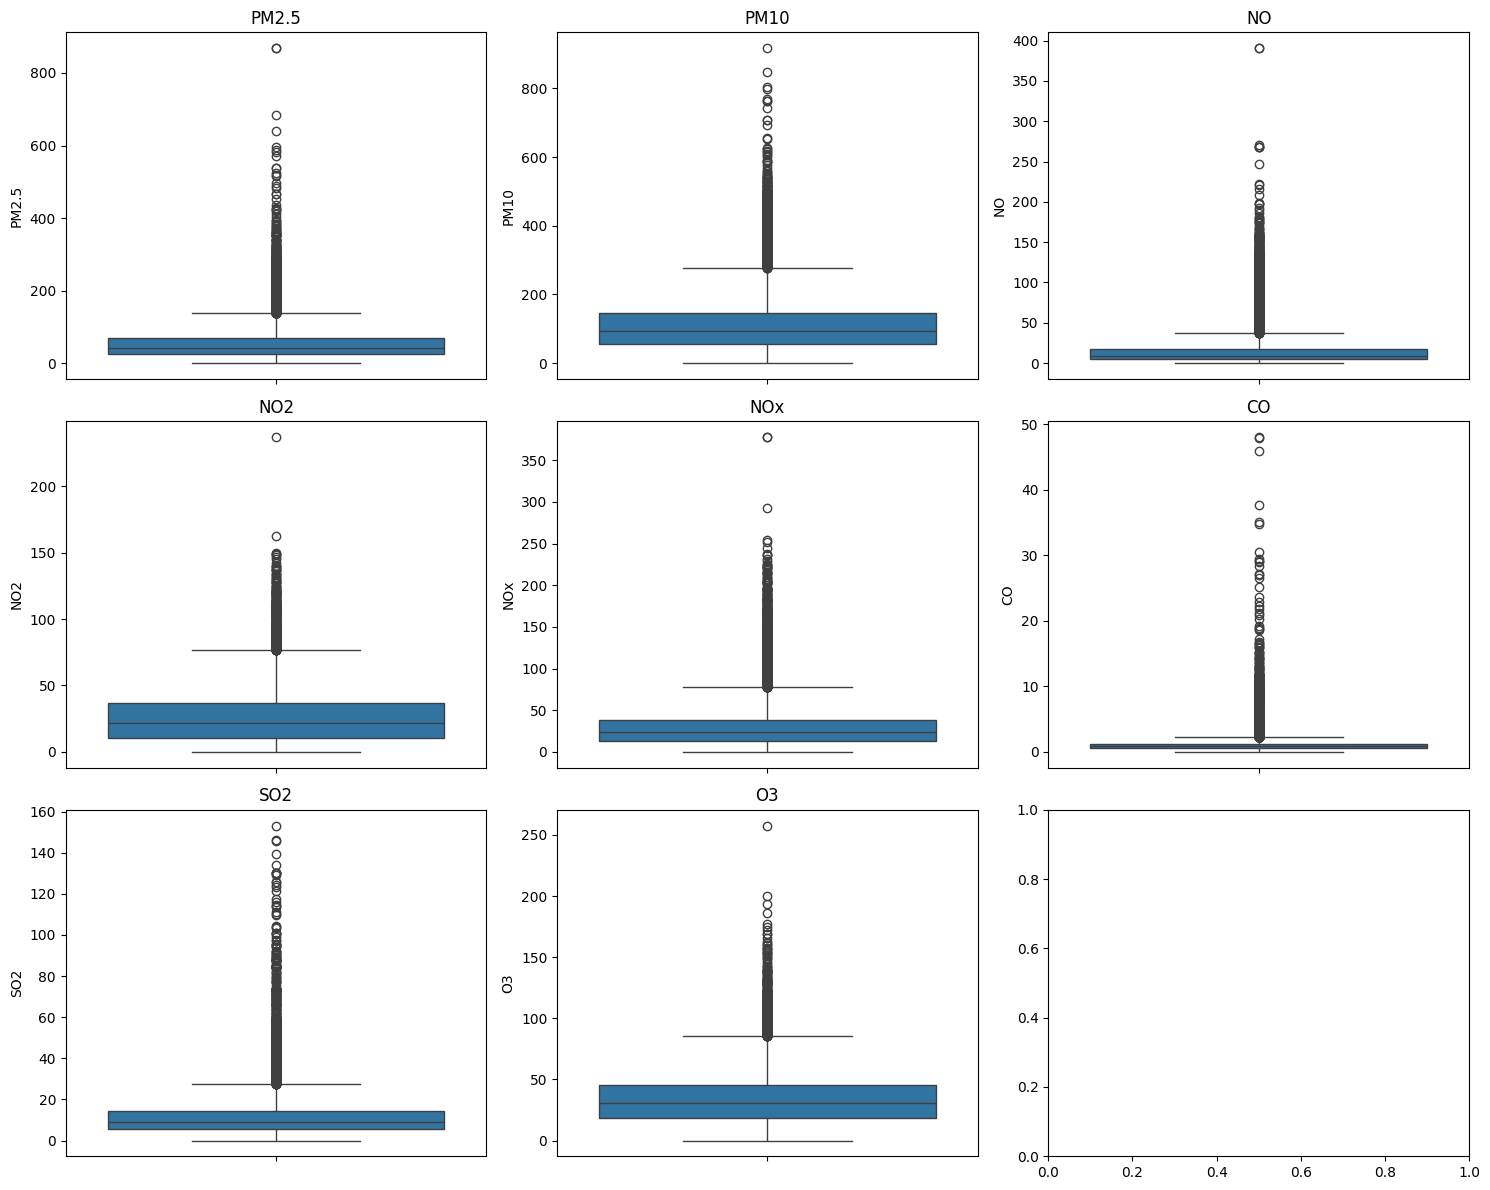

In [10]:
# 3. Outlier check (visual first, before cutting anything) -----------------
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, col in zip(axes.flatten(), pollutant_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

In [11]:
# 4. Target classes ----------------------------------------------------
df['AQI_Bucket'].value_counts()

AQI_Bucket
Satisfactory    6051
Moderate        6003
Poor            1500
Good            1266
Very Poor        917
Severe           315
Name: count, dtype: int64

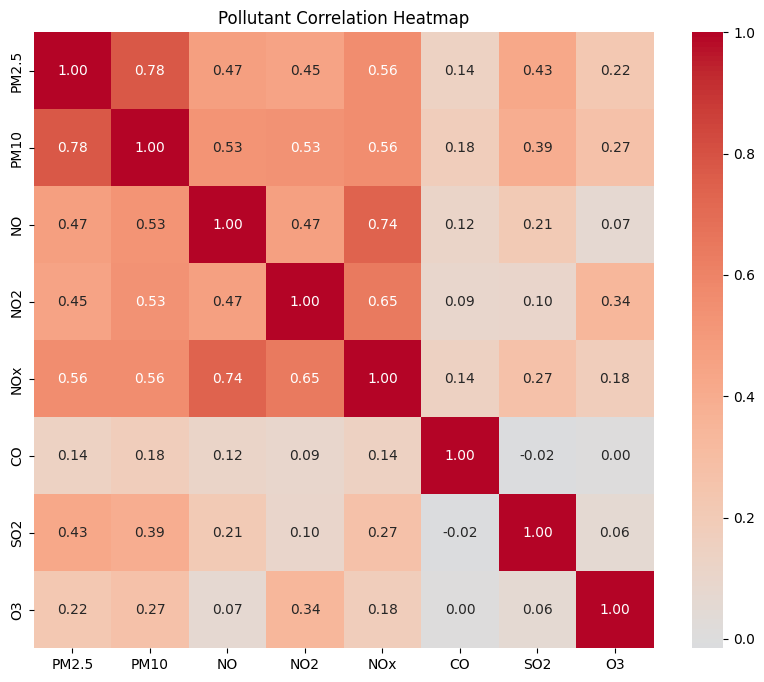

In [12]:
# Correlation heatmap across pollutants
plt.figure(figsize=(10, 8))
corr = df[pollutant_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Pollutant Correlation Heatmap')
plt.show()

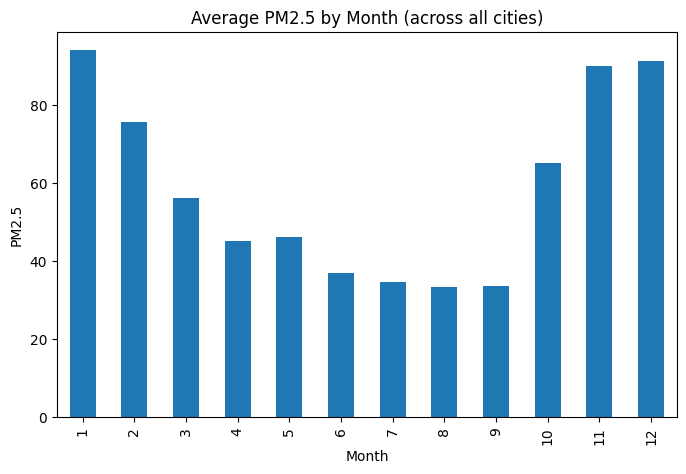

In [13]:
# Seasonal trend — extract month and look at PM2.5 patterns across the year
df['Month'] = df['Date'].dt.month
monthly_avg = df.groupby('Month')['PM2.5'].mean()

plt.figure(figsize=(8, 5))
monthly_avg.plot(kind='bar')
plt.title('Average PM2.5 by Month (across all cities)')
plt.ylabel('PM2.5')
plt.show()

In [14]:
# Feature engineering: season as a categorical feature
def get_season(month):
    if month in [12, 1, 2]:
        return 'Winter'
    elif month in [3, 4, 5]:
        return 'Summer'
    elif month in [6, 7, 8, 9]:
        return 'Monsoon'
    else:
        return 'Post-Monsoon'

df['Season'] = df['Month'].apply(get_season)
df['Season'].value_counts()

Season
Monsoon         4901
Summer          4662
Winter          4114
Post-Monsoon    2375
Name: count, dtype: int64

In [15]:
# One-hot encode City and Season for modeling later
df_encoded = pd.get_dummies(df, columns=['City', 'Season'], drop_first=True)
df_encoded.shape

(16052, 37)

In [16]:
# Time-based split: train on earlier years, test on most recent
train = df_encoded[df_encoded['Date'] < '2019-01-01']
val   = df_encoded[(df_encoded['Date'] >= '2019-01-01') & (df_encoded['Date'] < '2020-01-01')]
test  = df_encoded[df_encoded['Date'] >= '2020-01-01']

print(train.shape, val.shape, test.shape)

(7821, 37) (4901, 37) (3330, 37)


In [17]:
print("Train cities:", df[df['Date'] < '2019-01-01']['City'].nunique())
print("Test cities:", df[df['Date'] >= '2020-01-01']['City'].nunique())

Train cities: 12
Test cities: 20


In [18]:
def time_split_per_city(group, test_frac=0.15, val_frac=0.15):
    group = group.sort_values('Date')
    n = len(group)
    train_end = int(n * (1 - test_frac - val_frac))
    val_end = int(n * (1 - test_frac))
    return group.iloc[:train_end], group.iloc[train_end:val_end], group.iloc[val_end:]

train_list, val_list, test_list = [], [], []
for city, group in df.groupby('City'):
    tr, va, te = time_split_per_city(group)
    train_list.append(tr); val_list.append(va); test_list.append(te)

train = pd.concat(train_list)
val = pd.concat(val_list)
test = pd.concat(test_list)

print(train.shape, val.shape, test.shape)
print("Train cities:", train['City'].nunique(), "| Val cities:", val['City'].nunique(), "| Test cities:", test['City'].nunique())

(11227, 17) (2410, 17) (2415, 17)
Train cities: 20 | Val cities: 20 | Test cities: 20


In [19]:
# Now one-hot encode consistently across all three sets
train_encoded = pd.get_dummies(train, columns=['City', 'Season'], drop_first=True)
val_encoded = pd.get_dummies(val, columns=['City', 'Season'], drop_first=True)
test_encoded = pd.get_dummies(test, columns=['City', 'Season'], drop_first=True)

# Align columns in case any category is missing in one split
train_encoded, val_encoded = train_encoded.align(val_encoded, join='left', axis=1, fill_value=0)
train_encoded, test_encoded = train_encoded.align(test_encoded, join='left', axis=1, fill_value=0)

print(train_encoded.shape, val_encoded.shape, test_encoded.shape)

(11227, 37) (2410, 37) (2415, 37)


In [20]:
drop_cols = ['Date', 'AQI', 'AQI_Bucket']  # keep Month if you want finer granularity than Season

X_train = train_encoded.drop(columns=drop_cols)
y_train = train_encoded['AQI_Bucket']

X_val = val_encoded.drop(columns=drop_cols)
y_val = val_encoded['AQI_Bucket']

X_test = test_encoded.drop(columns=drop_cols)
y_test = test_encoded['AQI_Bucket']

print(X_train.shape, y_train.shape)

(11227, 34) (11227,)


In [21]:
import os
os.makedirs('data/processed', exist_ok=True)

X_train.to_csv('data/processed/X_train.csv', index=False)
y_train.to_csv('data/processed/y_train.csv', index=False)
X_val.to_csv('data/processed/X_val.csv', index=False)
y_val.to_csv('data/processed/y_val.csv', index=False)
X_test.to_csv('data/processed/X_test.csv', index=False)
y_test.to_csv('data/processed/y_test.csv', index=False)

print("Saved all splits to data/processed/")

Saved all splits to data/processed/


MODEL TAINING

In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                               confusion_matrix)
import pandas as pd
import numpy as np

# Check for any leftover missing values before modeling
print("Train NaNs:", X_train.isnull().sum().sum())
print("Val NaNs:", X_val.isnull().sum().sum())

Train NaNs: 12971
Val NaNs: 2278


In [23]:
# fill any remaining gaps with column median (from train only)
X_train = X_train.fillna(X_train.median())
X_val = X_val.fillna(X_train.median())
X_test = X_test.fillna(X_train.median())

In [24]:
# Scale features — fit ONLY on train, apply same scaler to val/test
# (fitting on val/test would leak information about their distribution)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [25]:
# Reusable evaluation function so all 3 models get judged identically
def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    f1_macro = f1_score(y_true, y_pred, average='macro')      # treats all classes equally
    f1_weighted = f1_score(y_true, y_pred, average='weighted') # accounts for class size

    print(f"\n{'='*50}")
    print(f"{name}")
    print(f"{'='*50}")
    print(f"Accuracy:     {acc:.4f}")
    print(f"F1 (macro):   {f1_macro:.4f}")
    print(f"F1 (weighted):{f1_weighted:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_true, y_pred))

    return {'model': name, 'accuracy': acc, 'f1_macro': f1_macro, 'f1_weighted': f1_weighted}

In [26]:
results = []

# 1. Logistic Regression
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_scaled, y_train)
y_pred_lr = lr.predict(X_val_scaled)
results.append(evaluate_model("Logistic Regression", y_val, y_pred_lr))

# 2. Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)  # no scaling needed
y_pred_dt = dt.predict(X_val)
results.append(evaluate_model("Decision Tree", y_val, y_pred_dt))

# 3. KNN
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred_knn = knn.predict(X_val_scaled)
results.append(evaluate_model("KNN", y_val, y_pred_knn))


Logistic Regression
Accuracy:     0.7490
F1 (macro):   0.6931
F1 (weighted):0.7392

Classification Report:
              precision    recall  f1-score   support

        Good       0.81      0.30      0.44       184
    Moderate       0.77      0.83      0.80       956
        Poor       0.66      0.57      0.61       276
Satisfactory       0.74      0.82      0.78       836
      Severe       0.84      0.76      0.80        34
   Very Poor       0.77      0.69      0.73       124

    accuracy                           0.75      2410
   macro avg       0.76      0.66      0.69      2410
weighted avg       0.75      0.75      0.74      2410


Decision Tree
Accuracy:     0.7394
F1 (macro):   0.6735
F1 (weighted):0.7380

Classification Report:
              precision    recall  f1-score   support

        Good       0.71      0.52      0.60       184
    Moderate       0.80      0.77      0.78       956
        Poor       0.59      0.60      0.60       276
Satisfactory       0.76      0

In [27]:
# Consolidated benchmark table
results_df = pd.DataFrame(results)
results_df.sort_values('f1_macro', ascending=False)

,model,accuracy,f1_macro,f1_weighted
0,Logistic Regression,0.748963,0.693067,0.739242
1,Decision Tree,0.739419,0.673517,0.738040
2,KNN,0.655602,0.616417,0.652454


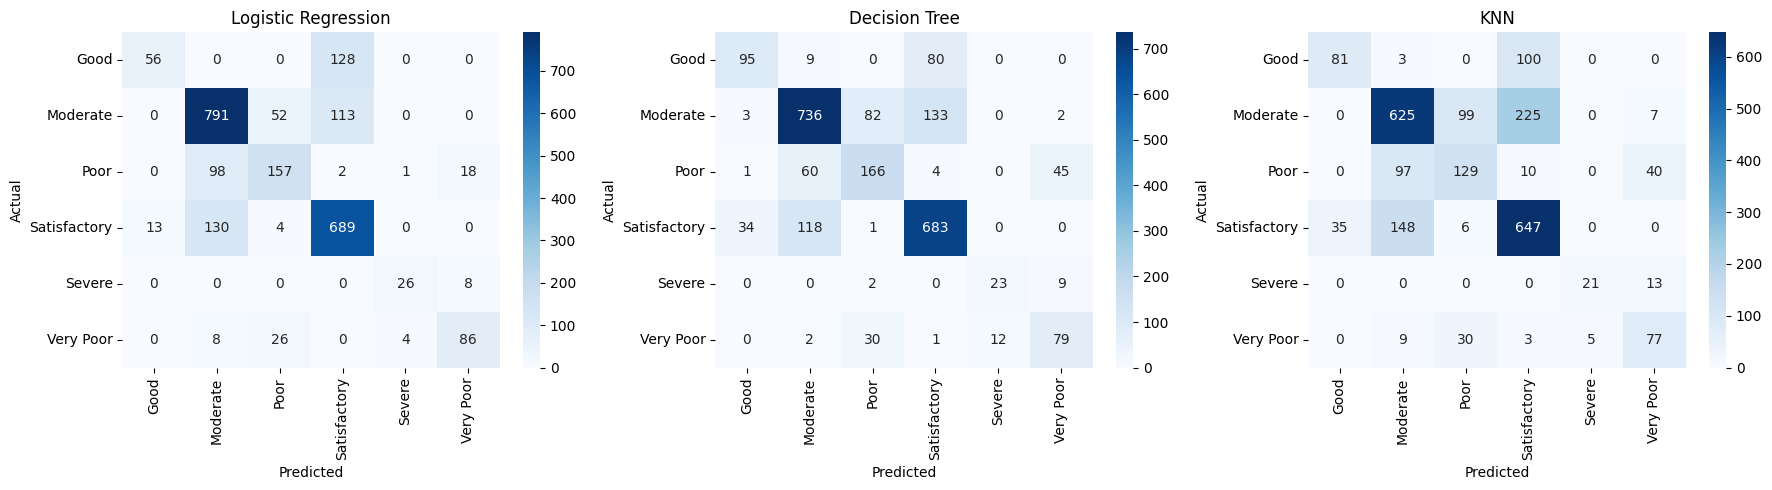

In [28]:
# Confusion matrices, side by side
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
preds = {'Logistic Regression': y_pred_lr, 'Decision Tree': y_pred_dt, 'KNN': y_pred_knn}
labels = sorted(y_train.unique())

for ax, (name, pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_val, pred, labels=labels)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=ax)
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [29]:
print(X_train.columns.tolist())

['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'Xylene', 'Month', 'City_Amaravati', 'City_Amritsar', 'City_Bengaluru', 'City_Bhopal', 'City_Brajrajnagar', 'City_Chandigarh', 'City_Coimbatore', 'City_Delhi', 'City_Ernakulam', 'City_Guwahati', 'City_Hyderabad', 'City_Jaipur', 'City_Jorapokhar', 'City_Kochi', 'City_Kolkata', 'City_Shillong', 'City_Talcher', 'City_Thiruvananthapuram', 'City_Visakhapatnam', 'Season_Post-Monsoon', 'Season_Summer', 'Season_Winter']


In [30]:
leak_check_cols = ['Benzene', 'Toluene', 'Xylene', 'NH3']
cols_present = [c for c in leak_check_cols if c in X_train.columns]
print("Found these that should've been dropped:", cols_present)

X_train = X_train.drop(columns=cols_present, errors='ignore')
X_val = X_val.drop(columns=cols_present, errors='ignore')
X_test = X_test.drop(columns=cols_present, errors='ignore')

print(X_train.shape, X_val.shape, X_test.shape)

Found these that should've been dropped: ['Benzene', 'Toluene', 'Xylene']
(11227, 31) (2410, 31) (2415, 31)


In [31]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb

results_v2 = []

# 1. Constrained Decision Tree — fixing the overfitting from before
dt_constrained = DecisionTreeClassifier(max_depth=10, min_samples_leaf=20, random_state=42)
dt_constrained.fit(X_train, y_train)
y_pred_dt2 = dt_constrained.predict(X_val)
results_v2.append(evaluate_model("Decision Tree (constrained)", y_val, y_pred_dt2))

# 2. Random Forest — no scaling needed, robust to skewed/outlier data
rf = RandomForestClassifier(n_estimators=200, max_depth=15, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_val)
results_v2.append(evaluate_model("Random Forest", y_val, y_pred_rf))

# 3. XGBoost — needs numeric labels, not strings
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_val_enc = le.transform(y_val)

xgb_model = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                random_state=42, eval_metric='mlogloss')
xgb_model.fit(X_train, y_train_enc)
y_pred_xgb_enc = xgb_model.predict(X_val)
y_pred_xgb = le.inverse_transform(y_pred_xgb_enc)  # convert back to readable labels
results_v2.append(evaluate_model("XGBoost", y_val, y_pred_xgb))


Decision Tree (constrained)
Accuracy:     0.7842
F1 (macro):   0.7376
F1 (weighted):0.7820

Classification Report:
              precision    recall  f1-score   support

        Good       0.72      0.51      0.60       184
    Moderate       0.85      0.80      0.82       956
        Poor       0.68      0.70      0.69       276
Satisfactory       0.77      0.86      0.81       836
      Severe       0.81      0.74      0.77        34
   Very Poor       0.76      0.70      0.73       124

    accuracy                           0.78      2410
   macro avg       0.76      0.72      0.74      2410
weighted avg       0.79      0.78      0.78      2410


Random Forest
Accuracy:     0.8087
F1 (macro):   0.7678
F1 (weighted):0.8053

Classification Report:
              precision    recall  f1-score   support

        Good       0.93      0.54      0.69       184
    Moderate       0.84      0.84      0.84       956
        Poor       0.71      0.65      0.68       276
Satisfactory       0.8

In [32]:
# Combine with your earlier baseline results for one full comparison table
all_results = pd.DataFrame(results + results_v2)
all_results.sort_values('f1_macro', ascending=False)

,model,accuracy,f1_macro,f1_weighted
5,XGBoost,0.816183,0.782478,0.814822
4,Random Forest,0.808714,0.767784,0.805308
3,Decision Tree (constrained),0.784232,0.737558,0.782007
0,Logistic Regression,0.748963,0.693067,0.739242
1,Decision Tree,0.739419,0.673517,0.738040
2,KNN,0.655602,0.616417,0.652454


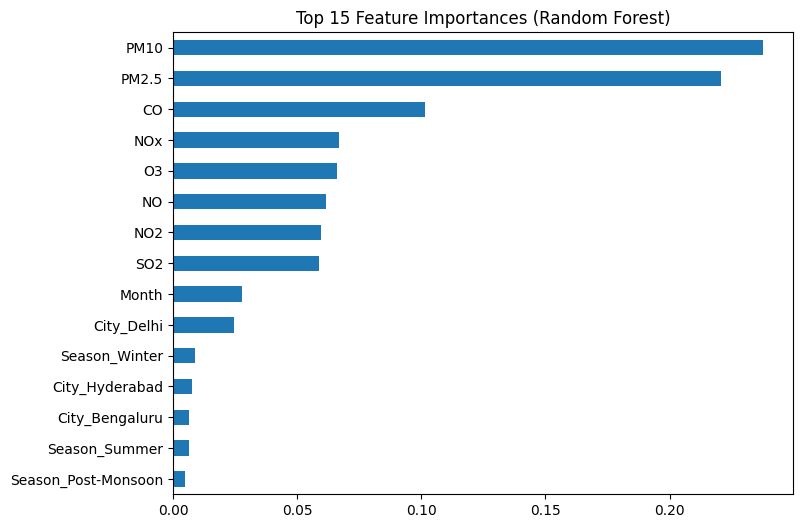

In [33]:
# Feature importance from Random Forest — worth checking which pollutants actually matter
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
importances.head(15).plot(kind='barh', figsize=(8, 6))
plt.title('Top 15 Feature Importances (Random Forest)')
plt.gca().invert_yaxis()
plt.show()

SMOTE

In [34]:
import sys
!"{sys.executable}" -m pip install imbalanced-learn --quiet


[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: C:\Program Files\Python312\python.exe -m pip install --upgrade pip


In [35]:
from imblearn.over_sampling import SMOTE
from collections import Counter

print("Before SMOTE:", Counter(y_train))

smote = SMOTE(random_state=42, k_neighbors=5)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print("After SMOTE:", Counter(y_train_smote))

Before SMOTE: Counter({'Moderate': 4333, 'Satisfactory': 4047, 'Poor': 1136, 'Very Poor': 742, 'Good': 715, 'Severe': 254})
After SMOTE: Counter({'Satisfactory': 4333, 'Good': 4333, 'Moderate': 4333, 'Poor': 4333, 'Very Poor': 4333, 'Severe': 4333})


In [36]:
# Re-train XGBoost on the SMOTE-balanced training set
y_train_smote_enc = le.transform(y_train_smote)  # reuse the same LabelEncoder from before

xgb_smote = xgb.XGBClassifier(n_estimators=200, max_depth=6, learning_rate=0.1,
                                random_state=42, eval_metric='mlogloss')
xgb_smote.fit(X_train_smote, y_train_smote_enc)

y_pred_xgb_smote_enc = xgb_smote.predict(X_val)
y_pred_xgb_smote = le.inverse_transform(y_pred_xgb_smote_enc)

result_smote = evaluate_model("XGBoost + SMOTE", y_val, y_pred_xgb_smote)


XGBoost + SMOTE
Accuracy:     0.8025
F1 (macro):   0.7873
F1 (weighted):0.8040

Classification Report:
              precision    recall  f1-score   support

        Good       0.72      0.79      0.75       184
    Moderate       0.87      0.78      0.82       956
        Poor       0.64      0.79      0.70       276
Satisfactory       0.82      0.84      0.83       836
      Severe       0.82      0.94      0.88        34
   Very Poor       0.78      0.69      0.74       124

    accuracy                           0.80      2410
   macro avg       0.77      0.81      0.79      2410
weighted avg       0.81      0.80      0.80      2410



In [37]:
# Direct before/after comparison
comparison = pd.DataFrame([
    {'model': 'XGBoost (no SMOTE)', 'accuracy': 0.816183, 'f1_macro': 0.782478, 'f1_weighted': 0.814822},
    result_smote
])
comparison

,model,accuracy,f1_macro,f1_weighted
0,XGBoost (no SMOTE),0.816183,0.782478,0.814822
1,XGBoost + SMOTE,0.802490,0.787289,0.804036


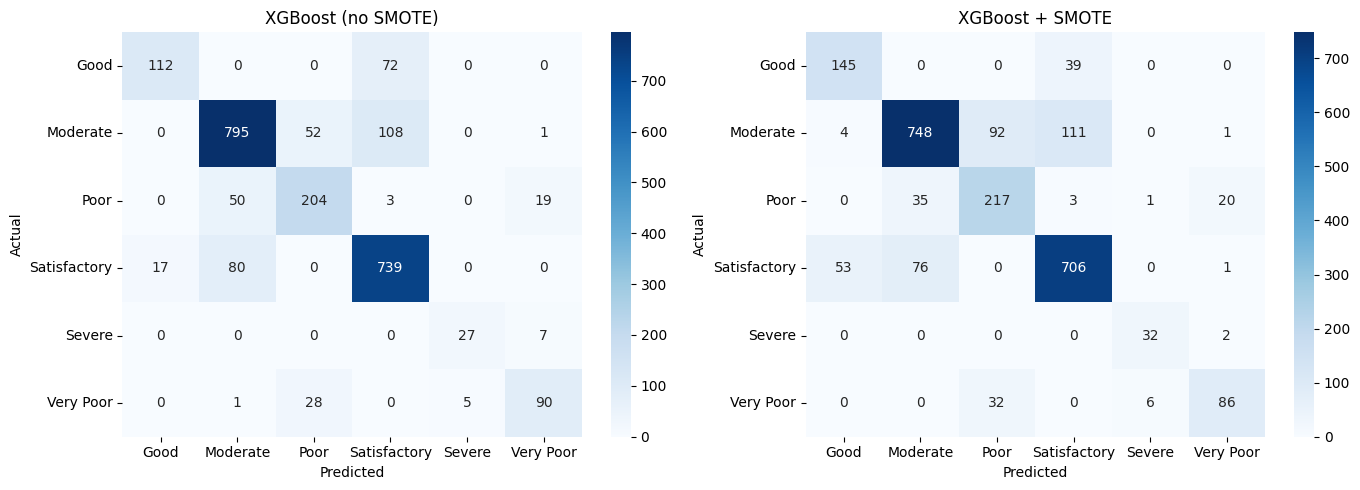

In [38]:
# Confusion matrix comparison, side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = sorted(y_train.unique())

cm_before = confusion_matrix(y_val, y_pred_xgb, labels=labels)  # your earlier XGBoost predictions
cm_after = confusion_matrix(y_val, y_pred_xgb_smote, labels=labels)

sns.heatmap(cm_before, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[0])
axes[0].set_title('XGBoost (no SMOTE)')
sns.heatmap(cm_after, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[1])
axes[1].set_title('XGBoost + SMOTE')

for ax in axes:
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [39]:
import joblib
import os

os.makedirs('models', exist_ok=True)

# Save the final model (XGBoost + SMOTE)
joblib.dump(xgb_smote, 'models/xgb_aqi_model.pkl')

# Save the LabelEncoder (converts AQI_Bucket text <-> numbers)
joblib.dump(le, 'models/label_encoder.pkl')

# Save the exact column order/names the model expects
joblib.dump(X_train.columns.tolist(), 'models/feature_columns.pkl')

# Save the list of pollutant columns (used to know which are numeric inputs)
joblib.dump(pollutant_cols, 'models/pollutant_columns.pkl')

# Save the list of cities and seasons the model was trained on (for the dropdown menus)
joblib.dump(sorted(df['City'].unique().tolist()), 'models/city_list.pkl')
joblib.dump(sorted(df['Season'].unique().tolist()), 'models/season_list.pkl')

print("Saved all model artifacts to models/")

Saved all model artifacts to models/


In [40]:
print(X_train.columns.tolist())

['PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'CO', 'SO2', 'O3', 'Month', 'City_Amaravati', 'City_Amritsar', 'City_Bengaluru', 'City_Bhopal', 'City_Brajrajnagar', 'City_Chandigarh', 'City_Coimbatore', 'City_Delhi', 'City_Ernakulam', 'City_Guwahati', 'City_Hyderabad', 'City_Jaipur', 'City_Jorapokhar', 'City_Kochi', 'City_Kolkata', 'City_Shillong', 'City_Talcher', 'City_Thiruvananthapuram', 'City_Visakhapatnam', 'Season_Post-Monsoon', 'Season_Summer', 'Season_Winter']


Callibration

In [41]:
from sklearn.calibration import CalibratedClassifierCV
import joblib

# Wrap your existing trained XGBoost+SMOTE model and calibrate its probabilities
calibrated_model = CalibratedClassifierCV(xgb_smote, method='isotonic', cv=3)
calibrated_model.fit(X_train_smote, y_train_smote_enc)

# Quick sanity check — compare macro F1 before/after calibration on validation set
y_pred_cal_enc = calibrated_model.predict(X_val)
y_pred_cal = le.inverse_transform(y_pred_cal_enc)
evaluate_model("XGBoost + SMOTE + Calibrated", y_val, y_pred_cal)

# Overwrite the saved model with the calibrated version
joblib.dump(calibrated_model, 'models/xgb_aqi_model.pkl')
print("Calibrated model saved")


XGBoost + SMOTE + Calibrated
Accuracy:     0.8025
F1 (macro):   0.7939
F1 (weighted):0.8026

Classification Report:
              precision    recall  f1-score   support

        Good       0.79      0.79      0.79       184
    Moderate       0.88      0.75      0.81       956
        Poor       0.70      0.77      0.73       276
Satisfactory       0.78      0.88      0.82       836
      Severe       0.81      0.88      0.85        34
   Very Poor       0.76      0.77      0.76       124

    accuracy                           0.80      2410
   macro avg       0.79      0.81      0.79      2410
weighted avg       0.81      0.80      0.80      2410

Calibrated model saved
